# UZK: автоэнкодер GRU → Conv1d

Запускайте из корня проекта с ядром `.venv` после `uv sync`.
Конфиг: `configs/uzk_gru_conv_autoencoder.yaml`. Целевой ряд не нужен.

Энкодер: `GRU → Conv1d(kernel_size=1)`.
Декодер: `Conv1d(kernel_size=1) → GELU → GRU → Linear`.
Сжимаются признаки; длина окна сохраняется. GRU учитывает прошлые точки
внутри окна. Декодер получает только латентную последовательность,
без скрытого состояния энкодера.


In [85]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from feature_selector import ExperimentRun, load_config, run_experiment
from feature_selector.artifacts import load_run
from feature_selector.data import load_features
from feature_selector.pipeline.data import prepare_data
from feature_selector.visualization import (
    plot_reconstruction_predictions,
    plot_training_history,
)

config = load_config(Path("configs/uzk_gru_conv_autoencoder.yaml"))
data = load_features(config.data["features_path"], config.data["freq"])


## Признаки для графиков

Обучение, реконструкция и метрики охватывают все входные признаки.
Для графиков используем только восемь признаков из прежних конфигов,
в указанном порядке. Этот список управляет только визуализацией.


In [86]:
plot_features = [
    "81TI10143",
    "81TI10126",
    "81FIL30066",
    "81LILH40012",
    "81TIH11209",
    "81FCL30063",
    "81FI30052",
    "81TI10123",
]
missing = [feature for feature in plot_features if feature not in data.X.columns]
if missing:
    raise ValueError(f"Missing plot features: {missing}")
print(f"Training features: {data.X.shape[1]}; plotted features: {len(plot_features)}")


Training features: 289; plotted features: 8


## Обучение

Скейлер и веса обучаются на train. Validation используется для выбора весов
и early stopping; test при обучении не используется.


In [87]:
run = run_experiment(config)
assert isinstance(run, ExperimentRun)
print(f"Результаты: {run.artifact_dir}")
pd.DataFrame.from_dict(
    {split: metrics["overall"] for split, metrics in run.metrics.items()},
    orient="index",
)


Результаты: /mnt/data/Projects/feature_selector_v3/runs/20261018T032844195442Z-aae9d738


,mae,rmse,r2,pearson,n,notes
train,311.974234,2415.928596,0.992753,0.996375,1361190,{}
validation,441.513089,2676.020077,0.992088,0.998581,495346,{}


## Сохранение модели для GRU

Экспортируем автоэнкодер вместе с обученным скейлером признаков, именами колонок
параметрами окон и информацией о периоде обучения. GRU-конфиг использует этот файл без переобучения энкодера.
Путь экспорта остаётся `runs/uzk_encoder.pkl`, как в исходном ноутбуке.
Повторный экспорт заменяет файл. После него запускайте
`Test_UZK_Autoencoder_GRU.ipynb` с тем же набором признаков и частотой.


In [88]:
encoder_path = run.pipeline.export_transform(
    Path("runs/uzk_gru_conv_encoder.pkl"), through="autoencoder", mode="encode"
)
print(f"Saved encoder pipeline: {encoder_path}")


Saved encoder pipeline: /mnt/data/Projects/feature_selector_v3/runs/uzk_gru_conv_encoder.pkl


## История обучения

Loss — MSE по всем точкам окон в единицах входа модели после скейлера.
Отчёты и графики реконструкции ниже — в исходных единицах и по последним точкам окон.
Суммарные метрики зависят от масштаба признаков; сравнивайте также метрики по признакам.


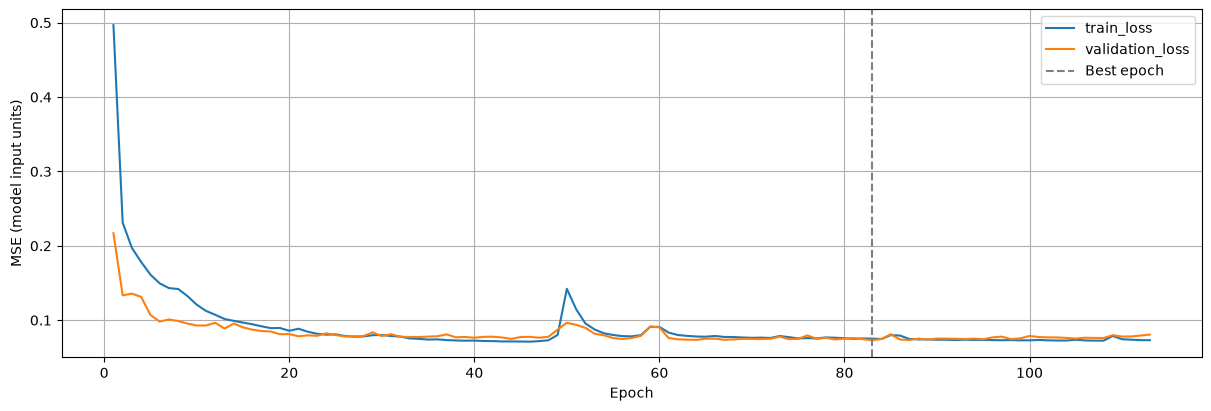

,mae,rmse,r2,pearson,n,notes
81TI10143,4.268974,5.311491,-2.822318,-0.049654,1714,{}
81TI10126,9.589574,14.220594,-0.545648,0.151276,1714,{}
81FIL30066,3172.117234,3906.301818,-1.999997,0.086586,1714,{}
81LILH40012,2.441036,2.914020,-0.341393,0.660667,1714,{}
81TIH11209,12.697932,18.277010,-0.194485,0.139531,1714,{}
81FCL30063,5365.919196,6887.500696,-0.395841,0.518011,1714,{}
81FI30052,1864.607871,2254.288930,0.122884,0.636404,1714,{}
81TI10123,1.631537,1.954591,-2.084999,-0.086503,1714,{}


In [89]:
ax = plot_training_history(run.model.history_, run.model.best_epoch_)
ax.set_ylabel("MSE (model input units)")
plt.show()

pd.DataFrame.from_dict(
    run.metrics["validation"]["per_feature"], orient="index"
).loc[plot_features]


## Реконструкция восьми выбранных признаков

Для каждого окна показываем последний исходный и восстановленный отсчёт.
Перекрывающиеся окна не усредняются; график каждого момента использует только
историю, доступную к этому моменту. Все значения — в исходных единицах.


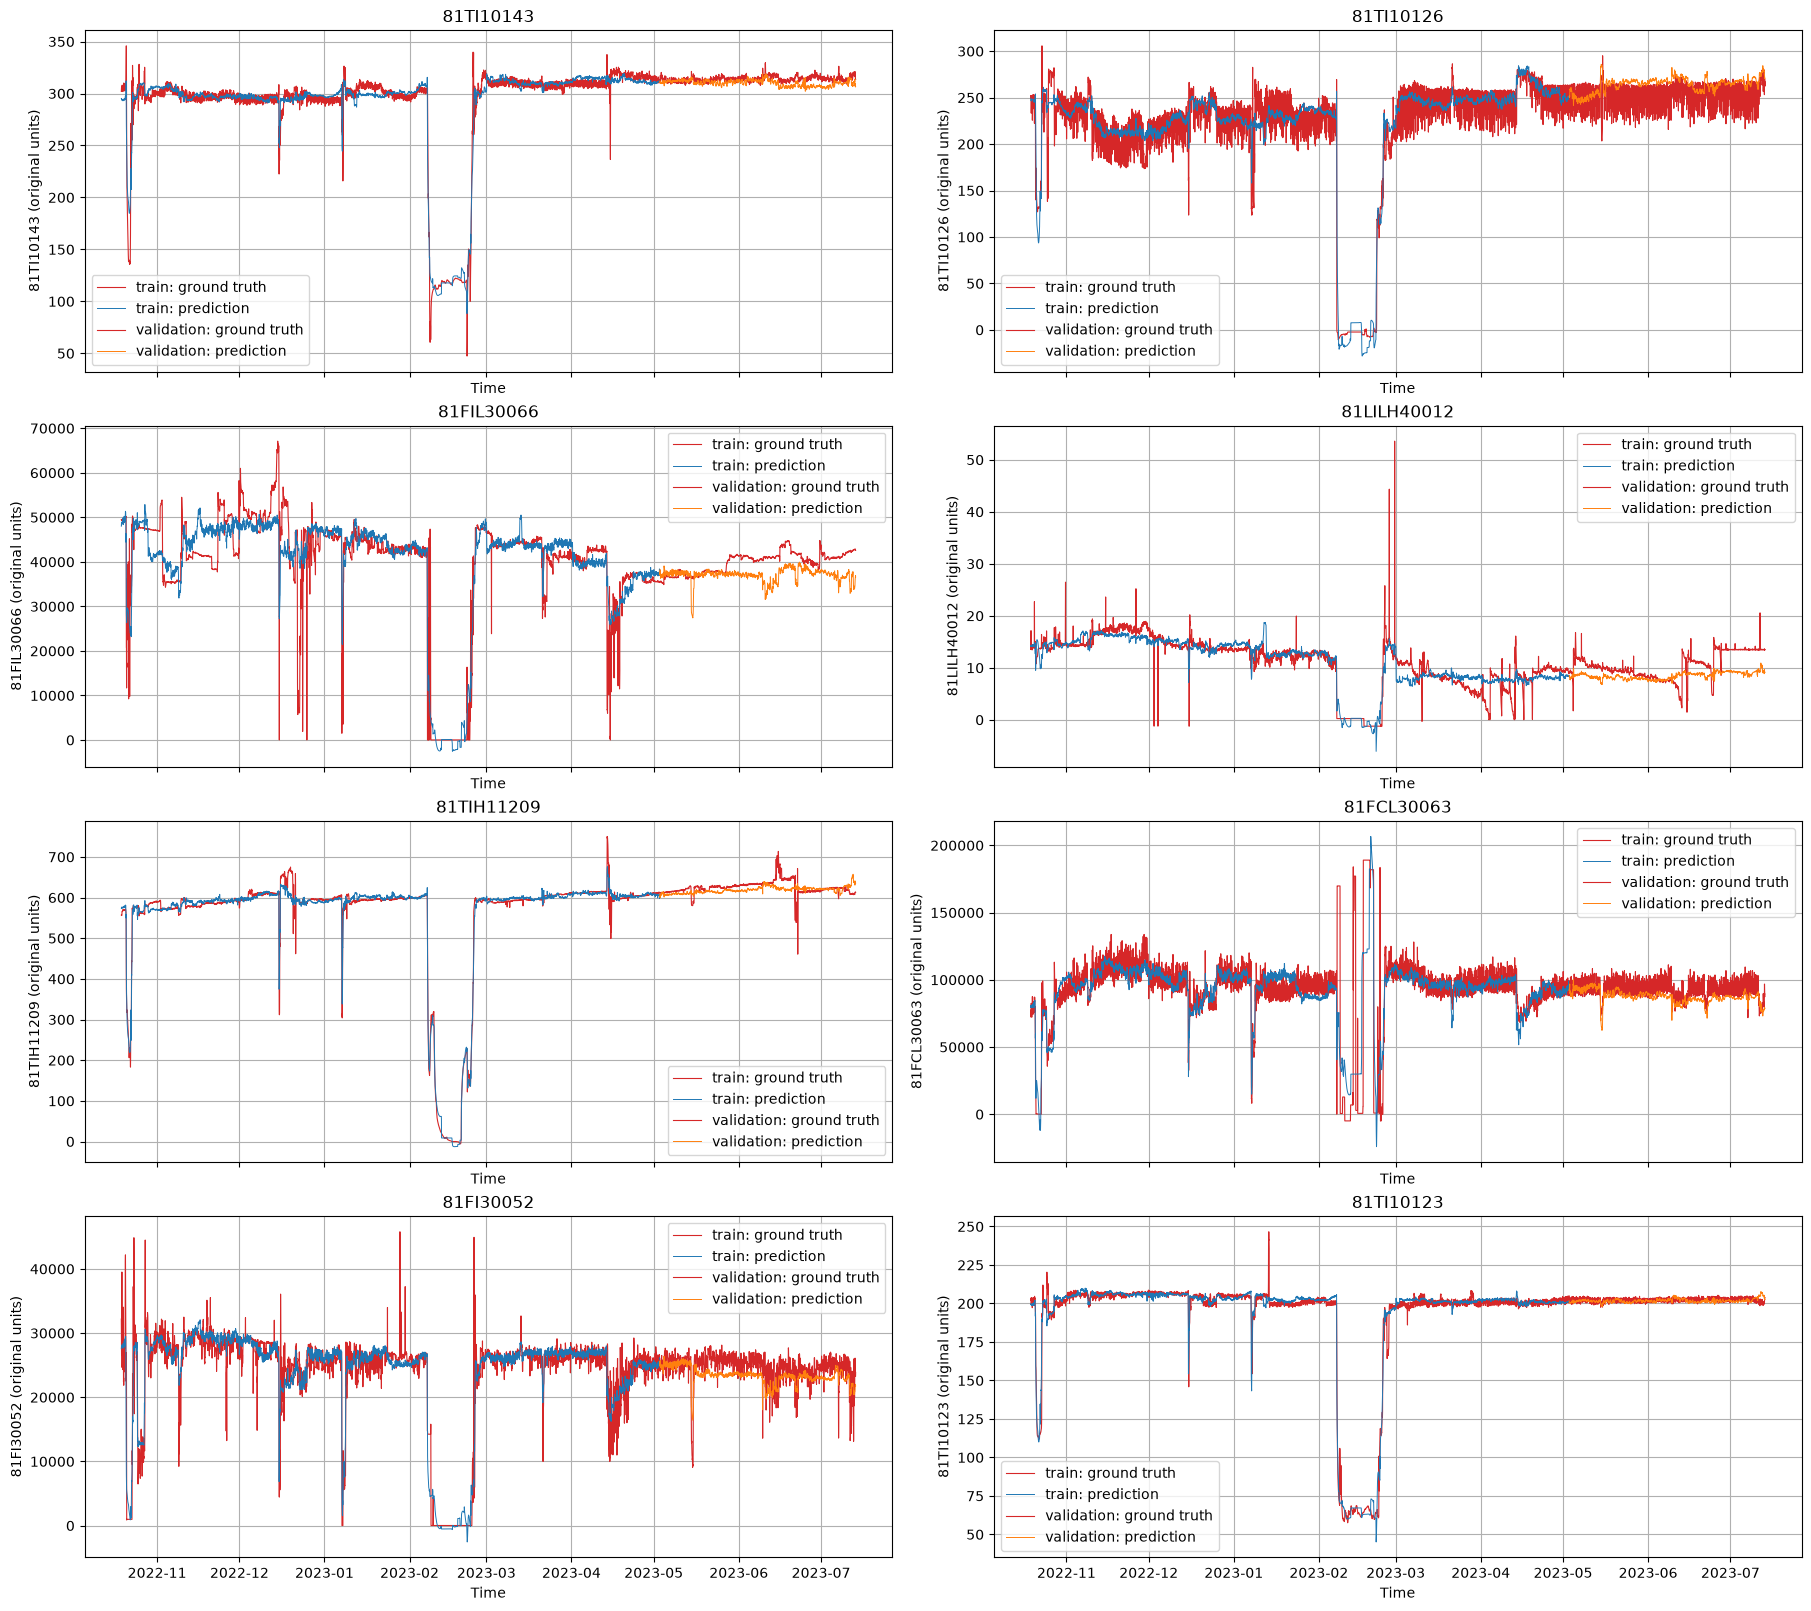

In [90]:
reports = dict(run.predictions)
fig, axes = plt.subplots(4, 2, figsize=(18, 16), sharex=True, layout="constrained")
for feature, ax in zip(plot_features, axes.flat):
    plot_reconstruction_predictions(reports, feature, ax=ax)
plt.show()


## Латентное представление

Окна: `(samples, lookback, features)`; выход энкодера:
`(samples, lookback, latent_channels)`. Прямой API модели
возвращает реконструкцию в единицах её входа; `run.predict` применяет обратный скейлер.


In [91]:
prepared = prepare_data(data, run.boundaries, config.data["freq"])
windows = run.pipeline.transform(prepared, through="windows").split("validation")
encoded = run.model.encode(windows.X)
reconstructed = run.model.decode(encoded)
print("Input:", windows.X.shape)
print("Encoded:", encoded.shape)
print("Reconstructed:", reconstructed.shape)


Input: (1714, 48, 289)
Encoded: (1714, 48, 8)
Reconstructed: (1714, 48, 289)


## Загрузка и явная оценка test

Следующая ячейка явно вычисляет test после завершения обучения.
Она не меняет обученные веса и автоматически сохранённые train/validation-отчёты.
Для прогнозирования цели с энкодером перед Ridge используйте
`configs/uzk_autoencoder_ridge.yaml`.


In [92]:
saved = load_run(run.artifact_dir)
assert isinstance(saved, ExperimentRun)
test_report = saved.predict(data, split="test")
print(f"Test feature-point pairs: {len(test_report)}")


Test feature-point pairs: 474249


Batch losses are stored in `history_` and streamed to JSONL and TensorBoard.
Run `tensorboard --logdir runs` to inspect training while it is running.

,epoch,batch,samples,train_loss,step,learning_rate
0,1,1,128,0.825443,1,0.01
1,1,2,128,1.009264,2,0.01
2,1,3,128,0.997007,3,0.01
3,1,4,128,0.889779,4,0.01
4,1,5,128,1.218631,5,0.01


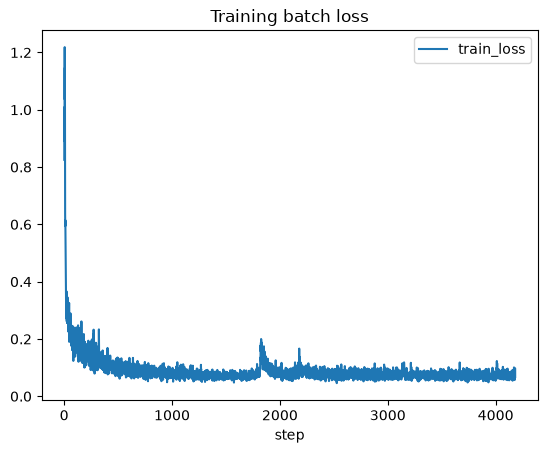

In [93]:
batch_history = pd.DataFrame([
    {"epoch": epoch["epoch"], **batch}
    for epoch in run.model.history_ for batch in epoch["batches"]
])
display(batch_history.head())
if not batch_history.empty:
    batch_history.plot(x="step", y="train_loss", title="Training batch loss")
    plt.show()
